# 03 · Train: CV model selection → calibration → held-out test → SHAP

* **Stage A** (head *any TLS*): 4 feature variants (rank / log × platform offset on / off), enet + corr.
* **Stage B** (both heads, best variant): signature (ssGSEA → LR), previous-model panel, kTSP, enet, LightGBM; selectors corr vs SHAP, both **inside** the folds.
* Calibration: Platt on out-of-fold predictions, per unit kind (bulk / Visium).
* Test: held-out patients; pathologist labels only; 95% bootstrap CI (Visium: sections resampled).
* OOD cohorts are **not** touched here (notebook 04).

In [1]:
import logging, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
(ROOT / "results").mkdir(exist_ok=True)
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s %(message)s",
                    handlers=[logging.StreamHandler(sys.stdout), logging.FileHandler(ROOT / "results" / "notebooks.log")],
                    force=True)
for noisy in ("anndata", "fsspec", "matplotlib", "PIL"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tls_model import pipeline
cfg = pipeline.load_config()
paths = {k: ROOT / v for k, v in cfg["paths"].items()}
FIG = paths["results"] / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
import pickle, time
from tls_model import prepare, evaluate

units, meta = prepare.load_units(cfg, ROOT)
obs = units.obs
fc = cfg["features"]
CV = dict(n_folds=cfg["split"]["cv_folds"], seed=cfg["split"]["seed"], n_panel=fc["n_panel"], n_pair_genes=fc["n_pair_genes"])
assert not (obs.loc[pipeline.train_rows(obs, "any"), "split"] != "train").any()
print(units.shape, "| previous-model panel genes in feature space:",
      len(set(meta["prev_panel_genes"]) & set(meta["genes"])), "/", len(meta["prev_panel_genes"]))

(48310, 5049) | previous-model panel genes in feature space: 178 / 236


## Stage A — feature variants

In [3]:
stage_a = []
for variant in fc["variants"]:
    B, names = pipeline.feature_matrix(units, meta, variant["representation"], variant["offset"])
    table, _ = pipeline.run_cv(B, names, obs, "any", cfg["models"]["stage_a"], meta, **CV)
    stage_a.append({**variant, **table.iloc[0][["auroc_bulk", "auroc_spot", "auroc_bulk_pooled", "score"]].to_dict()})
    del B
stage_a = pd.DataFrame(stage_a).sort_values("score", ascending=False)
stage_a.to_csv(paths["results"] / "cv_stage_a.tsv", sep="\t", index=False)
best_variant = stage_a.iloc[0][["representation", "offset"]].to_dict()
print("best variant:", best_variant)
stage_a

2026-10-09 14:04:34,028 INFO tls_model.pipeline CV any enet|corr: {'auroc_bulk': 0.588, 'auroc_spot': 0.736, 'auroc_bulk_pooled': 0.739, 'auroc_bulk_not_prev_cohorts': 0.588, 'score': 0.662, 'seconds': 19.0}


2026-10-09 14:05:29,744 INFO tls_model.pipeline CV any enet|corr: {'auroc_bulk': 0.637, 'auroc_spot': 0.784, 'auroc_bulk_pooled': 0.728, 'auroc_bulk_not_prev_cohorts': 0.637, 'score': 0.71, 'seconds': 14.9}


2026-10-09 14:06:07,243 INFO tls_model.pipeline CV any enet|corr: {'auroc_bulk': 0.633, 'auroc_spot': 0.664, 'auroc_bulk_pooled': 0.677, 'auroc_bulk_not_prev_cohorts': 0.633, 'score': 0.649, 'seconds': 15.8}


2026-10-09 14:06:38,007 INFO tls_model.pipeline CV any enet|corr: {'auroc_bulk': 0.606, 'auroc_spot': 0.719, 'auroc_bulk_pooled': 0.727, 'auroc_bulk_not_prev_cohorts': 0.606, 'score': 0.662, 'seconds': 13.5}


best variant: {'representation': 'rank', 'offset': False}


,representation,offset,auroc_bulk,auroc_spot,auroc_bulk_pooled,score
1,rank,False,0.636996,0.783740,0.728287,0.710368
3,log,False,0.606080,0.718807,0.727476,0.662443
0,rank,True,0.587762,0.735949,0.739258,0.661855
2,log,True,0.633438,0.663736,0.677292,0.648587


## Stage B — model ladder × selectors, both heads

In [4]:
B, names = pipeline.feature_matrix(units, meta, best_variant["representation"], bool(best_variant["offset"]))
print("base features:", B.shape)
cv_tables, oof, best = {}, {}, {}
for head in ("any", "mature"):
    t0 = time.time()
    cv_tables[head], oof[head] = pipeline.run_cv(B, names, obs, head, cfg["models"]["stage_b"], meta,
                                                 prev_excluded=cfg["cohorts"]["prev_panel_derived_on"], **CV)
    best[head] = pipeline.best_candidate(cv_tables[head])
    cv_tables[head].to_csv(paths["results"] / f"cv_stage_b_{head}.tsv", sep="\t", index=False)
    print(head, "best:", best[head], f"({(time.time() - t0) / 60:.1f} min)")

base features: (48310, 5514)


2026-10-09 14:07:10,419 INFO tls_model.pipeline CV any signature|-: {'auroc_bulk': 0.627, 'auroc_spot': 0.782, 'auroc_bulk_pooled': 0.779, 'auroc_bulk_not_prev_cohorts': 0.629, 'score': 0.705, 'seconds': 1.3}


2026-10-09 14:07:17,321 INFO tls_model.pipeline CV any prev_panel|-: {'auroc_bulk': 0.601, 'auroc_spot': 0.587, 'auroc_bulk_pooled': 0.712, 'auroc_bulk_not_prev_cohorts': 0.589, 'score': 0.594, 'seconds': 6.9}


2026-10-09 14:07:50,387 INFO tls_model.pipeline CV any ktsp|corr: {'auroc_bulk': 0.632, 'auroc_spot': 0.785, 'auroc_bulk_pooled': 0.783, 'auroc_bulk_not_prev_cohorts': 0.631, 'score': 0.709, 'seconds': 33.1}


2026-10-09 14:10:22,537 INFO tls_model.pipeline CV any ktsp|shap: {'auroc_bulk': 0.568, 'auroc_spot': 0.777, 'auroc_bulk_pooled': 0.767, 'auroc_bulk_not_prev_cohorts': 0.555, 'score': 0.672, 'seconds': 152.1}


...

2026-10-09 14:16:18,757 INFO tls_model.pipeline CV mature enet|corr: {'auroc_bulk': 0.539, 'auroc_spot': 0.513, 'auroc_bulk_pooled': 0.494, 'auroc_bulk_not_prev_cohorts': 0.555, 'score': 0.526, 'seconds': 2.4}


2026-10-09 14:17:30,307 INFO tls_model.pipeline CV mature enet|shap: {'auroc_bulk': 0.456, 'auroc_spot': 0.58, 'auroc_bulk_pooled': 0.522, 'auroc_bulk_not_prev_cohorts': 0.395, 'score': 0.518, 'seconds': 71.5}


2026-10-09 14:17:33,815 INFO tls_model.pipeline CV mature lgbm|corr: {'auroc_bulk': 0.526, 'auroc_spot': 0.642, 'auroc_bulk_pooled': 0.577, 'auroc_bulk_not_prev_cohorts': 0.515, 'score': 0.584, 'seconds': 3.5}


2026-10-09 14:17:37,804 INFO tls_model.pipeline CV mature lgbm|shap: {'auroc_bulk': 0.41, 'auroc_spot': 0.584, 'auroc_bulk_pooled': 0.455, 'auroc_bulk_not_prev_cohorts': 0.383, 'score': 0.497, 'seconds': 4.0}


mature best: {'family': 'lgbm', 'selector': 'corr'} (2.6 min)


In [5]:
cols = ["candidate", "auroc_bulk", "auroc_spot", "auroc_bulk_pooled", "auroc_bulk_not_prev_cohorts", "score", "seconds"]
print("auroc_bulk = mean within-cohort AUROC (selection); auroc_bulk_pooled = all cohorts pooled (for reference)")
print("head A: P(any TLS)"); display(cv_tables["any"][cols].round(3))
print("head B: P(mature | TLS)"); display(cv_tables["mature"][cols].round(3))

auroc_bulk = mean within-cohort AUROC (selection); auroc_bulk_pooled = all cohorts pooled (for reference)
head A: P(any TLS)


,candidate,auroc_bulk,auroc_spot,auroc_bulk_pooled,auroc_bulk_not_prev_cohorts,score,seconds
0,lgbm|shap,0.610,0.853,0.772,0.626,0.731,18.3
1,enet|corr,0.637,0.784,0.728,0.645,0.710,14.8
2,lgbm|corr,0.585,0.834,0.767,0.592,0.709,17.8
3,ktsp|corr,0.632,0.785,0.783,0.631,0.709,33.1
4,signature|-,0.627,0.782,0.779,0.629,0.705,1.3
5,ktsp|shap,0.568,0.777,0.767,0.555,0.672,152.1
6,prev_panel|-,0.601,0.587,0.712,0.589,0.594,6.9
7,enet|shap,0.524,0.513,0.455,0.537,0.518,229.2


head B: P(mature | TLS)


,candidate,auroc_bulk,auroc_spot,auroc_bulk_pooled,auroc_bulk_not_prev_cohorts,score,seconds
0,lgbm|corr,0.526,0.642,0.577,0.515,0.584,3.5
1,prev_panel|-,0.544,0.575,0.464,0.652,0.559,1.5
2,enet|corr,0.539,0.513,0.494,0.555,0.526,2.4
3,enet|shap,0.456,0.580,0.522,0.395,0.518,71.5
4,signature|-,0.421,0.578,0.449,0.390,0.500,0.4
5,lgbm|shap,0.410,0.584,0.455,0.383,0.497,4.0
6,ktsp|corr,0.446,0.517,0.502,0.367,0.481,4.7
7,ktsp|shap,0.420,0.512,0.506,0.315,0.466,66.9


> **Head B (maturity) is an experiment, not part of the deployed output.** With block-stratified CV it shows no signal (bulk within-cohort and USZ spot AUROC ≈ 0.4–0.6; even germinal-centre signatures give ≈ 0.5 on bulk). The deployed model returns *no TLS / TLS + confidence* only (notebook 04).

## Final models (refit on all train patients) + calibration

In [6]:
final, calibrators, p = {}, {}, {}
not_ood = (obs["split"] != "ood").to_numpy()
for head in ("any", "mature"):
    name = pipeline.candidate_name(best[head])
    final[head], calibrators[head] = pipeline.fit_final(B, names, obs, head, best[head], oof[head][name], meta,
                                                        CV["n_panel"], CV["n_pair_genes"], CV["seed"])
    p[head] = np.full(len(obs), np.nan)
    p[head][not_ood] = pipeline.predict(B[not_ood], names, obs[not_ood], final[head], calibrators[head])

(ROOT / "models").mkdir(exist_ok=True)
with open(ROOT / "models" / "tls_model.pkl", "wb") as handle:
    pickle.dump({"variant": best_variant, "best": best, "models": final, "calibrators": calibrators}, handle)
print({h: final[h].panel[:10] for h in final})

{'any': ['gene:IGHG1', 'genepair:CCL19*CD79A', 'gene:IGHG4', 'gene:IGHM', 'gene:CD37', 'gene:ADIRF', 'gene:ISG20', 'sig:TLS_Solid', 'gene:PLXNB2', 'gene:BANK1'], 'mature': ['genepair:PAX5*FCRL5', 'gene:PAX5', 'genepair:PAX5*IL2', 'gene:NET1', 'genepair:C1orf54*PRNP', 'genepair:PAX5*SKAP1', 'gene:COL4A4', 'genepair:IL2*CD22', 'gene:PCDHGA9', 'gene:AP1M2']}


## Held-out test (in-distribution)

In [7]:
test = pipeline.evaluate_split(obs, p["any"], p["mature"], "test")
test.to_csv(paths["results"] / "test_metrics.tsv", sep="\t", index=False)
evaluate.metrics_table(test.to_dict("records"))

,split,head,block,n,n_pos,auroc,auprc,brier,balanced_accuracy,spearman
0,test,any,bulk:CPTAC-ccRCC,17.0,5.0,"0.700 [0.433, 0.933]","0.444 [0.200, 0.900]","0.210 [0.110, 0.332]",NaN,NaN
1,test,any,bulk:MGH_LUAD_DagogoJack,3.0,2.0,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.088 [0.070, 0.126]",NaN,NaN
2,test,any,bulk:TCGA-BRCA,31.0,18.0,"0.491 [0.242, 0.702]","0.599 [0.415, 0.817]","0.245 [0.195, 0.295]",NaN,NaN
3,test,any,bulk:TCGA-KIRC/KIRP/KICH,42.0,5.0,"0.584 [0.214, 0.976]","0.385 [0.056, 0.859]","0.114 [0.060, 0.173]",NaN,NaN
4,test,any,bulk:TCGA-LUAD,45.0,32.0,"0.466 [0.278, 0.669]","0.693 [0.537, 0.879]","0.220 [0.168, 0.276]",NaN,NaN
5,test,any,bulk:TCGA-PAAD,24.0,18.0,"0.454 [0.195, 0.719]","0.796 [0.626, 0.943]","0.209 [0.128, 0.293]",NaN,NaN
6,test,any,bulk:all,162.0,80.0,"0.757 [0.679, 0.827]","0.705 [0.600, 0.808]","0.192 [0.163, 0.225]",NaN,NaN
7,test,any,visium:spots,25206.0,374.0,"0.930 [0.886, 0.960]","0.306 [0.143, 0.492]","0.013 [0.006, 0.022]",NaN,NaN
8,test,any,visium:sections,7.0,6.0,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.339 [0.164, 0.449]",NaN,NaN
9,test,mature,bulk:MGH_LUAD_DagogoJack,2.0,0.0,,,,NaN,NaN


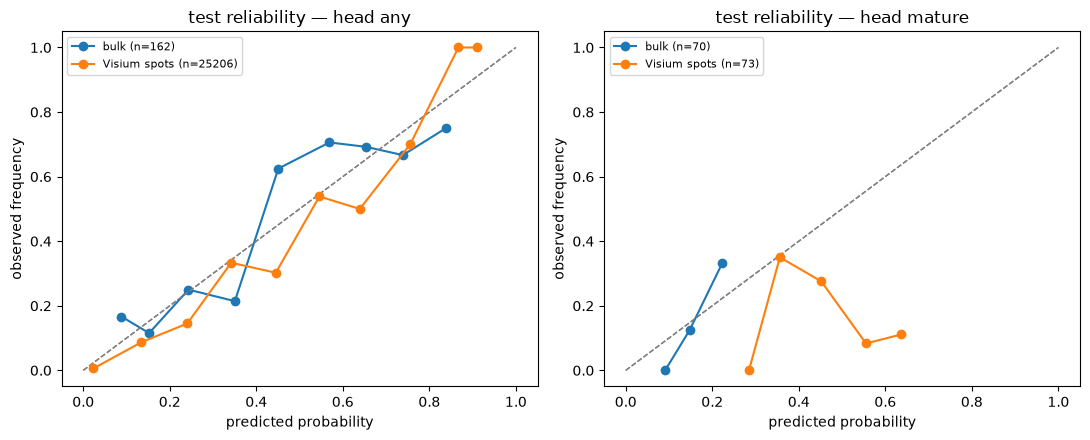

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, head in zip(axes, ("any", "mature")):
    scored = pipeline.scored_rows(obs, head, "test")
    y = obs[pipeline.HEAD_LABEL[head]].to_numpy(dtype=float)
    for kind, mask in (("bulk", obs["kind"] == "bulk"), ("Visium spots", obs["unit"] == "spot")):
        m = scored & mask.to_numpy()
        if m.sum() > 10 and len(np.unique(y[m])) == 2:
            evaluate.reliability_curve(ax, y[m], p[head][m], kind)
    ax.set_title(f"test reliability — head {head}")
fig.tight_layout(); fig.savefig(FIG / "03_reliability_test.png", dpi=120)

## Diagnostics: P(TLS) of TLS-negative bulk samples by cohort (should not differ much)

In [9]:
neg = (obs["kind"] == "bulk").to_numpy() & (obs["tls_any"] == 0).to_numpy() & not_ood
pd.DataFrame({"cohort": obs["cohort"][neg], "p_any": p["any"][neg]}).groupby("cohort")["p_any"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
cohort,,,,,,,,
,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CPTAC-PAAD,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CPTAC-ccRCC,61.0,0.176,0.064,0.091,0.135,0.158,0.200,0.471
Internal_lung,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MGH_LUAD_DagogoJack,3.0,0.200,0.158,0.099,0.109,0.119,0.250,0.382
TCGA-BRCA,217.0,0.350,0.091,0.165,0.286,0.340,0.396,0.700
TCGA-KIRC/KIRP/KICH,187.0,0.165,0.071,0.054,0.114,0.152,0.200,0.457
TCGA-LUAD,106.0,0.445,0.112,0.258,0.377,0.431,0.470,0.841
TCGA-PAAD,29.0,0.363,0.198,0.185,0.243,0.296,0.330,0.809


## Leave-one-cohort-out (robustness only, not used for selection)

In [10]:
loco = pipeline.leave_one_cohort_out(B, names, obs, best["any"], meta, CV["n_panel"], CV["n_pair_genes"], CV["seed"])
loco.to_csv(paths["results"] / "loco.tsv", sep="\t", index=False)
loco.round(3)

2026-10-09 14:20:41,506 INFO tls_model.pipeline LOCO CPTAC-ccRCC auroc=0.534


2026-10-09 14:21:24,019 INFO tls_model.pipeline LOCO MGH_LUAD_DagogoJack auroc=0.926


2026-10-09 14:22:06,932 INFO tls_model.pipeline LOCO TCGA-BRCA auroc=0.579


2026-10-09 14:22:52,636 INFO tls_model.pipeline LOCO TCGA-KIRC/KIRP/KICH auroc=0.615


2026-10-09 14:23:34,187 INFO tls_model.pipeline LOCO TCGA-LUAD auroc=0.628


2026-10-09 14:24:18,451 INFO tls_model.pipeline LOCO TCGA-PAAD auroc=0.554


,left_out,n,n_pos,auroc
0,CPTAC-ccRCC,86,25,0.534
1,MGH_LUAD_DagogoJack,12,9,0.926
2,TCGA-BRCA,153,89,0.579
3,TCGA-KIRC/KIRP/KICH,210,23,0.615
4,TCGA-LUAD,221,158,0.628
5,TCGA-PAAD,118,89,0.554


## SHAP of the final models

Computed on a random sample of train units (bulk + Visium). Feature prefixes: `gene:` gene, `sig:` ssGSEA score, `sigpair:` signature × signature, `genepair:` gene × gene.

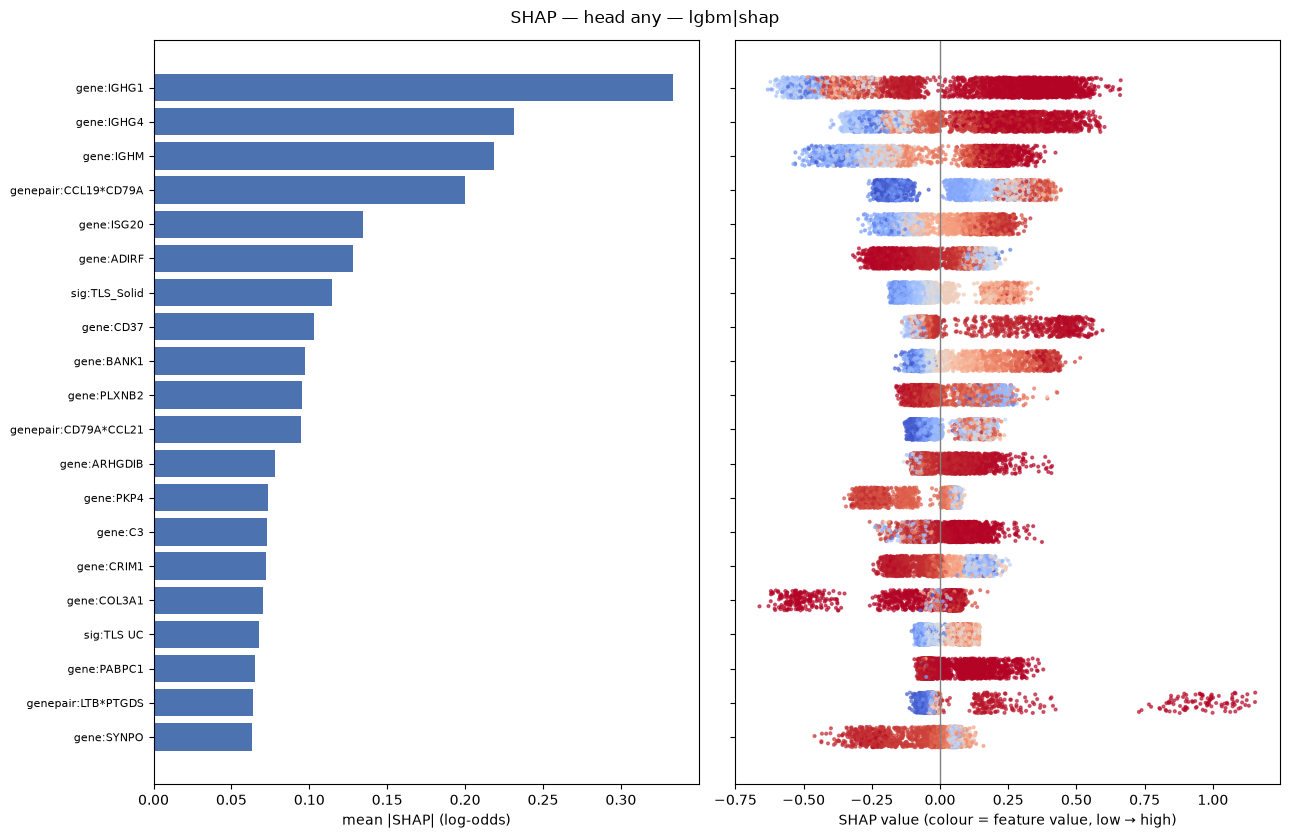

,feature,mean_abs_shap
0,gene:IGHG1,0.3333
1,gene:IGHG4,0.2316
2,gene:IGHM,0.2184
3,genepair:CCL19*CD79A,0.2001
4,gene:ISG20,0.1347
5,gene:ADIRF,0.1277
6,sig:TLS_Solid,0.1146
7,gene:CD37,0.1032
8,gene:BANK1,0.0974
9,gene:PLXNB2,0.0953


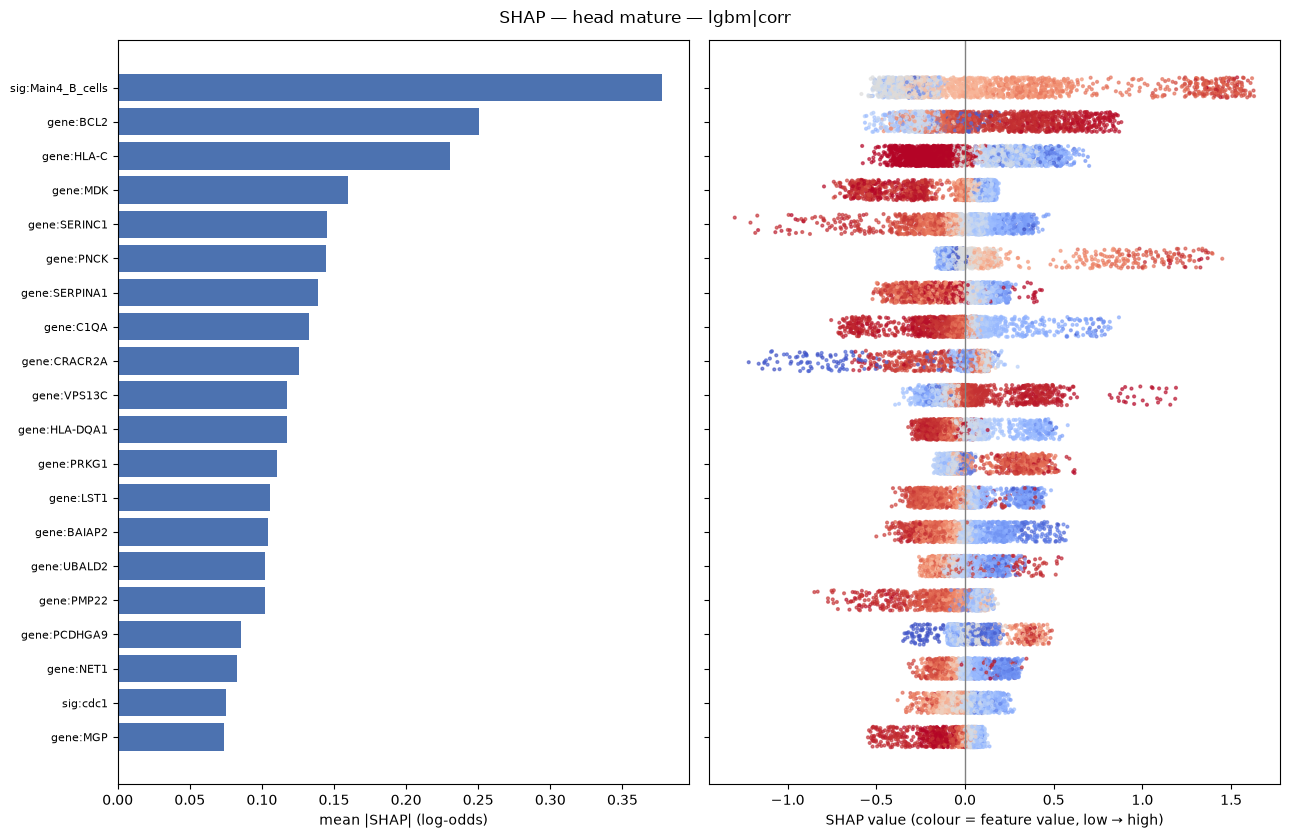

,feature,mean_abs_shap
0,sig:Main4_B_cells,0.3772
1,gene:BCL2,0.2504
2,gene:HLA-C,0.2304
3,gene:MDK,0.1597
4,gene:SERINC1,0.1451
5,gene:PNCK,0.1446
6,gene:SERPINA1,0.1386
7,gene:C1QA,0.1328
8,gene:CRACR2A,0.1255
9,gene:VPS13C,0.1175


In [11]:
rng = np.random.default_rng(0)
shap_models = dict(final)
for head in ("any", "mature"):
    if best[head]["family"] != "lgbm":   # the best LightGBM as a reference view
        lgbm = cv_tables[head][cv_tables[head]["family"] == "lgbm"].iloc[0]
        cand = {"family": "lgbm", "selector": lgbm["selector"]}
        shap_models[f"{head} (lgbm ref)"] = pipeline.fit_final(B, names, obs, head, cand, oof[head][lgbm["candidate"]],
                                                               meta, CV["n_panel"], CV["n_pair_genes"], CV["seed"])[0]
for label, model in shap_models.items():
    head = label.split()[0]
    rows = np.flatnonzero(pipeline.train_rows(obs, head))
    sample = rng.choice(rows, size=min(4000, len(rows)), replace=False)
    out = model.shap_values(B[sample], names)
    if out is None:
        print(label, ": kTSP has no SHAP; pairs =", [(model.panel[i], model.panel[j]) for i, j, _ in model.model.pairs])
        continue
    fig, ranking = evaluate.shap_summary(*out, title=f"SHAP — head {label} — {model.family}|{model.selector}")
    tag = label.replace(" ", "_").replace("(", "").replace(")", "")
    fig.savefig(FIG / f"03_shap_{tag}.png", dpi=120)
    ranking.to_csv(paths["results"] / f"shap_{tag}.tsv", sep="\t", index=False)
    plt.show()
    display(ranking.head(15).round(4))